Saving waterQuality1.csv to waterQuality1 (2).csv

================ RUNNING FAST RFE ================



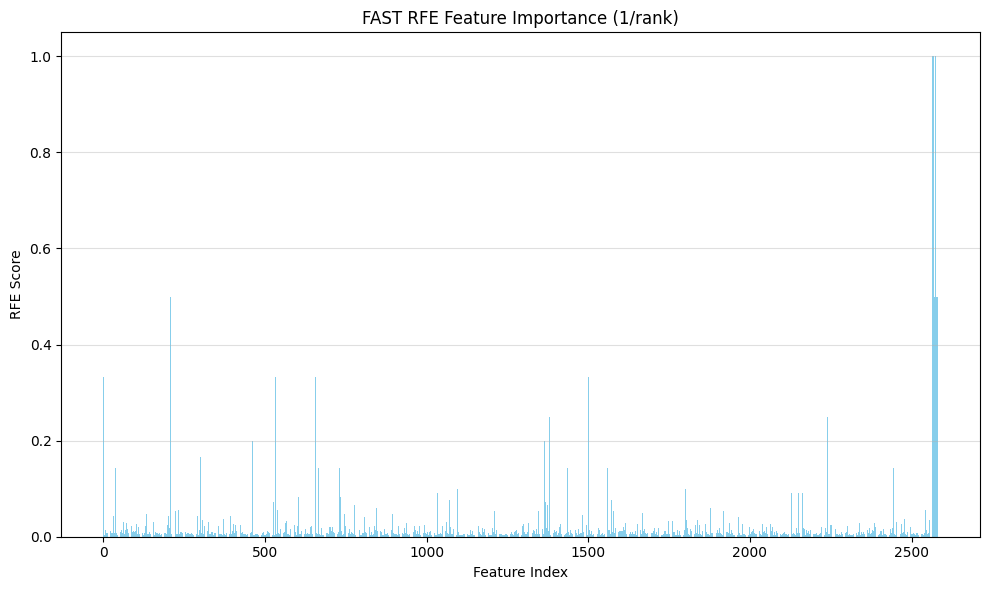


================ MODEL COMPARISON ================

Logistic Regression Accuracy: 90.00%
Perceptron Accuracy: 88.38%
CART Accuracy: 94.25%
Random Forest Accuracy: 95.00%
GBM Accuracy: 95.25%

Baseline RF Accuracy: 89.44%


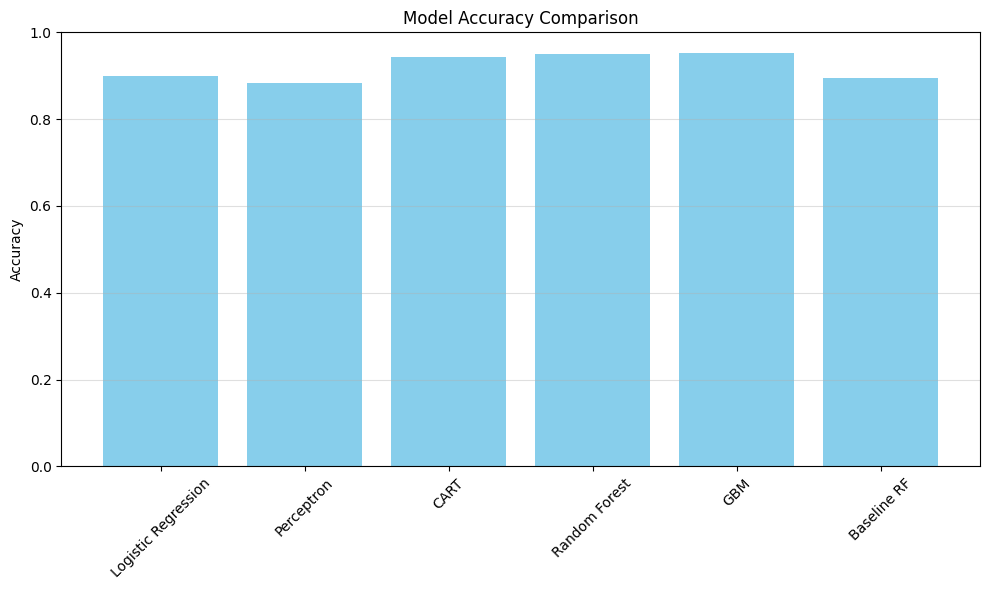


========= FINAL ACCURACY SUMMARY =========
Logistic Regression  : 90.00%
Perceptron           : 88.38%
CART                 : 94.25%
Random Forest        : 95.00%
GBM                  : 95.25%
Baseline RF          : 89.44%


In [4]:
# ================================================
# FAST RFE + MODEL COMPARISON + BAR PLOT
# (Uses RandomForest for RFE → MUCH FASTER)
# ================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files
uploaded = files.upload()

from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

from sklearn.linear_model import LogisticRegression, Perceptron
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.feature_selection import RFE

# ---------------------------------------------------------
# Load dataset
# ---------------------------------------------------------
filename = list(uploaded.keys())[0]
df = pd.read_csv(filename)

# Separate features & target
X = df.iloc[:, :-1]
y = df.iloc[:, -1]

# Encode target
y = LabelEncoder().fit_transform(y)

# Identify categorical columns
cat_cols = X.select_dtypes(include=['object', 'category']).columns

# Only encode categorical columns → MUCH smaller matrix
ct = ColumnTransformer(
    [('ohe', OneHotEncoder(handle_unknown='ignore'), cat_cols)],
    remainder='passthrough'
)
X_enc = ct.fit_transform(X)

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X_enc, y, test_size=0.2, random_state=42
)

# ========================================================
# FAST RFE USING RANDOM FOREST (much faster than LR)
# ========================================================

print("\n================ RUNNING FAST RFE ================\n")

rf_estimator = RandomForestClassifier(n_estimators=150, random_state=42)

# Reduce features by removing 10 at a time
rfe = RFE(estimator=rf_estimator, n_features_to_select=15, step=10)
rfe.fit(X_train, y_train)

# Feature importance scores (1/rank)
rfe_scores = 1 / rfe.ranking_

# Plot RFE feature ranking
plt.figure(figsize=(10,6))
plt.bar(range(len(rfe_scores)), rfe_scores, color='skyblue')
plt.title("FAST RFE Feature Importance (1/rank)")
plt.xlabel("Feature Index")
plt.ylabel("RFE Score")
plt.grid(axis='y', alpha=0.4)
plt.tight_layout()
plt.show()

# Apply RFE selection
X_train_rfe = rfe.transform(X_train)
X_test_rfe = rfe.transform(X_test)

# ========================================================
# MODEL COMPARISON
# ========================================================

print("\n================ MODEL COMPARISON ================\n")

models = {
    "Logistic Regression": LogisticRegression(solver='liblinear'),
    "Perceptron": Perceptron(max_iter=2000),
    "CART": DecisionTreeClassifier(),
    "Random Forest": RandomForestClassifier(n_estimators=200),
    "GBM": GradientBoostingClassifier()
}

accs = {}

for name, model in models.items():
    model.fit(X_train_rfe, y_train)
    acc = accuracy_score(y_test, model.predict(X_test_rfe))
    accs[name] = acc
    print(f"{name} Accuracy: {acc*100:.2f}%")

# Baseline RF using all features
baseline = RandomForestClassifier(n_estimators=200, random_state=42)
baseline.fit(X_train, y_train)
baseline_acc = accuracy_score(y_test, baseline.predict(X_test))
accs["Baseline RF"] = baseline_acc

print(f"\nBaseline RF Accuracy: {baseline_acc*100:.2f}%")

# ========================================================
# BAR PLOT FOR ACCURACY (FIXED)
# ========================================================

plt.figure(figsize=(10,6))
plt.bar(accs.keys(), accs.values(), color='skyblue')
plt.title("Model Accuracy Comparison")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.grid(axis='y', alpha=0.4)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# ========================================================
# Summary
# ========================================================

print("\n========= FINAL ACCURACY SUMMARY =========")
for k, v in accs.items():
    print(f"{k:20s} : {v*100:.2f}%")
